# Notebook 4 — Klasterisasi & Mesin Peringkasan Hybrid TF-IDF
**Proyek UTS Kecerdasan Artifisial: Agen Cerdas Peringkas Laporan Banjir**
Izvio Prijaya Mumin (2611600087) · Fatah Idzhar Hamdi (2611600129) · Universitas Budi Luhur

Ini adalah **inti proyek** (tema: *Mesin Peringkasan & Klasterisasi*). Agen menerima ribuan tweet banjir, lalu:
1. **Mengelompokkan** tweet berdasarkan kemiripan isi (unsupervised: K-Means vs Agglomerative Clustering).
2. **Mengenali** klaster yang berisi laporan kejadian memakai model Naive Bayes dari Notebook 2.
3. **Meringkas** setiap klaster menjadi beberapa tweet paling representatif dengan **Hybrid TF-IDF** (Sharifi dkk., 2010).
4. **Mengevaluasi** ringkasan dengan ROUGE terhadap ringkasan acuan buatan manusia, dibanding baseline.

Korpus: 43.023 tweet banjir mentah 2018–2023 (Ariyanto dkk., 2025), difokuskan ke wilayah **Jabodetabek**.

**Reprodusibilitas.** Klasterisasi sensitif terhadap pembulatan angka di SVD dan K-Means. Agar Colab dan laptop menghasilkan
klaster yang sama, sel pertama (1) memasang versi library yang sama (`requirements.txt`), (2) membatasi komputasi ke 1 thread,
dan (3) memaksa OpenBLAS memakai kernel CPU yang sama (Haswell/AVX2). Di Colab, sel ini memasang library lalu **me-restart
runtime sekali**; setelah restart, jalankan **Runtime → Run all** lagi.

In [1]:
import os, subprocess, sys
if "numpy" in sys.modules:
    print("⚠ numpy sudah dimuat sebelum sel ini; pengaturan BLAS mungkin tidak berlaku. Restart runtime lalu Run all.")
for v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[v] = "1"                      # urutan penjumlahan tidak bergantung jumlah core
os.environ["OPENBLAS_CORETYPE"] = "Haswell"  # kernel BLAS sama di laptop (AVX2) dan server Colab (AVX-512)
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/repo").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/izviopm/uts-ai-banjir-ciledug.git", "/content/repo"], check=True)
    os.chdir("/content/repo")
    # buang output run sebelumnya agar acuan (JSON & label) selalu versi repo, bukan hasil Colab yang lalu
    subprocess.run("git fetch -q && git reset -q --hard origin/main", shell=True, check=True)
    from importlib.metadata import version, PackageNotFoundError
    def cocok(baris):
        nama, ver = baris.split("==")
        try:
            return version(nama) == ver
        except PackageNotFoundError:
            return False
    syarat = [b.strip() for b in open("requirements.txt") if "==" in b and not b.startswith("#")]
    if not all(map(cocok, syarat)):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *syarat], check=True)
        print("Library acuan terpasang. Runtime di-restart; jalankan Runtime → Run all sekali lagi.")
        os.kill(os.getpid(), 9)
elif Path("../data").exists():
    os.chdir("..")
sys.path.insert(0, "notebooks")

In [2]:
import json, math, random, re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import teks
from threadpoolctl import threadpool_limits
threadpool_limits(1)  # jaga-jaga bila variabel lingkungan thread tidak terbaca

sns.set_theme(style="whitegrid")
FIG = Path("laporan/gambar"); FIG.mkdir(parents=True, exist_ok=True)
EXPORT = Path("web/public/model"); EXPORT.mkdir(parents=True, exist_ok=True)
REF = Path("data/reference"); REF.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option("display.max_colwidth", 150)

# Lingkungan acuan: hasil klasterisasi sensitif terhadap versi library (struktur klaster lemah, silhouette < 0,1),
# sehingga versi dicatat. Hasil resmi (laporan, web, Supabase) berasal dari lingkungan yang tercetak di output repo ini.
from importlib.metadata import version
print("Python", sys.version.split()[0], "|", ", ".join(f"{p} {version(p)}" for p in ["numpy", "pandas", "scikit-learn", "scipy", "Sastrawi"]))
f_acuan = EXPORT / "klaster_ringkasan.json"
klaster_acuan = json.loads(f_acuan.read_text(encoding="utf8")) if f_acuan.exists() else None  # versi di repo, sebelum ditimpa

Python 3.14.7 | numpy 2.5.4, pandas 3.1.0, scikit-learn 1.9.1, scipy 1.18.1, Sastrawi 1.0.1


## 1. Korpus: tweet banjir Jabodetabek
Penyaringan:
1. Menyebut wilayah Jabodetabek (Jakarta, Bogor, Depok, Tangerang, Bekasi, Ciledug, Ciliwung, Kali Angke).
2. Membuang tweet berbahasa Melayu (penanda leksikal, sama seperti Notebook 1) dan berbahasa Inggris (≥ 2 kata fungsi Inggris).
3. Preprocessing dengan modul yang sama (`teks.py`), lalu membuang duplikat dan tweet dengan < 3 kata bermakna.

In [3]:
raw = pd.read_csv("data/raw/mendeley-srl-crisis/flood-with-english-translation.csv")
raw["waktu"] = pd.to_datetime(raw.created_at, errors="coerce", utc=True)
raw = raw[raw.waktu.notna()].rename(columns={"full_text_in_Indonesian": "text_raw"})
raw = raw.dropna(subset=["text_raw"])  # 5 tweet tanpa teks; di pandas 2.x (Colab) NaN membuat filter str.contains gagal
print("Korpus mentah:", len(raw))

WILAYAH = r"jakarta|tangerang|ciledug|bekasi|depok|bogor|jabodetabek|\bdki\b|kali angke|ciliwung"
INGGRIS = {"the", "and", "is", "are", "to", "of", "that", "it", "you", "my", "was", "for", "with", "this", "like", "what"}
df = raw[raw.text_raw.str.lower().str.contains(WILAYAH, regex=True)].copy()
n0 = len(df)
df = df[df.text_raw.map(teks.skor_melayu) == 0]
df = df[df.text_raw.map(lambda t: len(set(teks.bersihkan(t).split()) & INGGRIS) < 2)]
n1 = len(df)
df["text_clean"] = df.text_raw.map(teks.preprocess)
df = df.drop_duplicates("text_clean")
df = df[df.text_clean.str.split().str.len() >= 3].reset_index(drop=True)
print(f"Jabodetabek: {n0} → tanpa Melayu/Inggris: {n1} → unik & ≥3 kata: {len(df)}")
df[["waktu", "text_raw", "text_clean"]].to_json("data/processed/korpus_jabodetabek.json", orient="records", force_ascii=False, indent=0)
df[["waktu", "text_raw", "text_clean"]].sample(5, random_state=SEED)

Korpus mentah: 43018


Jabodetabek: 3491 → tanpa Melayu/Inggris: 3444 → unik & ≥3 kata: 3390


C:\Users\izvio.prijaya\AppData\Local\Temp\ipykernel_19960\1023544054.py:18: Pandas4Warning: The default formatting of datetime/timedelta values will change from numbers ("epoch") to strings ("iso") in a future version. Specify `date_format="iso"` explicitly in the `to_json()` call to opt-in to the future behaviour and silence this warning.
  df[["waktu", "text_raw", "text_clean"]].to_json("data/processed/korpus_jabodetabek.json", orient="records", force_ascii=False, indent=0)


,waktu,text_raw,text_clean
134,2018-03-04 09:05:17+00:00,Dpc Xtc Cirebon Kota memberikan bantuan kepada Korban banjir di desa Ciledug wetan Kab.Cirebon https://t.co/p02Mive3fr @XTC__Indonesia @ENewsIn...,dpc xtc cirebon kota beri bantu korban banjir desa ciledug wetan kab cirebon
1764,2020-12-24 17:18:18+00:00,Ikut prihatin dgn yg terjadi di Bandung hari ini semoga banjir cepat surut dan nasyarakat terdampak segera tertangani. Insya Allah Kang @ridwanka...,ikut prihatin bandung hari moga banjir cepat surut nasyarakat dampak segera tangan insya allah kang fokus tangan baik beda jakarta banyak manusia ...
2465,2022-03-19 17:05:29+00:00,Sifat air itu cair dan hanya bisa mengalir dari hulu ke hilir Mengatasi banjir Jakarta itu cuma satu ganti Gub juga Wagub nya - Wooiii @ArizaPat...,sifat air cair alir hulu hilir atas banjir jakarta cuma satu ganti gub wagub wooiii lu kira air macam buruh lu atur angka shift
1987,2021-03-11 12:55:58+00:00,OK-OCE gagal. DP 0 Rp gagal dikorupsi pula. Monumen bambu dibongkar. Gabion dibongkar. Trotoar bongkar pasang. Cat jalan diganti2. Peti mati...,oce gagal dp angka rp gagal korupsi monumen bambu bongkar gabion bongkar trotoar bongkar pasang cat jalan ganti angka peti mati tidak resap air ba...
1295,2020-02-26 21:42:11+00:00,Duh...dia pikir warga Jakarta yg kena banjir ini apa Kok disuruh nikmati banjir ??!! Sontoloyo emang nih orang Bolotnisasi Dua pertiga otaknya Bo...,duh pikir warga jakarta kena banjir apa suruh nikmat banjir sontoloyo emang orang bolotnisasi tiga otak bolot


## 2. Penanda laporan dari model Naive Bayes (Notebook 2)
Model diekspor sebagai JSON di Notebook 2; di sini dipakai dengan perhitungan manual yang sama dengan web.
Model ini **bukan penyaring keras** (presisi ~0,6), tetapi dipakai untuk mengukur proporsi laporan di setiap klaster.

In [4]:
nb = json.loads((EXPORT / "naive_bayes.json").read_text())
nb_idx = {w: i for i, w in enumerate(nb["vocab"])}
nb_idf, nb_flp, nb_prior = np.array(nb["idf"]), np.array(nb["feature_log_prob"]), np.array(nb["class_log_prior"])

def peluang_laporan(teks_bersih):
    tok = teks_bersih.split()
    tf = Counter(nb_idx[g] for g in tok + [" ".join(p) for p in zip(tok, tok[1:])] if g in nb_idx)
    if not tf:
        return 0.0
    v = {i: (1 + math.log(c)) * nb_idf[i] for i, c in tf.items()}
    n = math.sqrt(sum(x * x for x in v.values()))
    s = [nb_prior[k] + sum(x / n * nb_flp[k][i] for i, x in v.items()) for k in (0, 1)]
    return float(1 / (1 + math.exp(s[0] - s[1])))

df["p_laporan"] = df.text_clean.map(peluang_laporan)
df["laporan"] = df.p_laporan >= 0.5
print(f"Diprediksi laporan: {df.laporan.sum()} dari {len(df)} ({df.laporan.mean():.1%})")

Diprediksi laporan: 539 dari 3390 (15.9%)


## 3. Representasi: TF-IDF + LSA
- **TF-IDF** unigram, `min_df=3` (buang kata langka), `max_df=0.5` (buang kata yang ada di >50% tweet, termasuk "banjir").
- **LSA** (Latent Semantic Analysis = TruncatedSVD) mereduksi ribuan dimensi kata menjadi 100 dimensi topik laten,
  lalu dinormalisasi L2. Jarak Euclidean pada vektor ternormalisasi setara dengan jarak cosine, sehingga K-Means bekerja lebih baik
  daripada langsung di TF-IDF yang sangat jarang (*sparse*).

In [5]:
tfidf = TfidfVectorizer(min_df=3, max_df=0.5, sublinear_tf=True)
X_tfidf = tfidf.fit_transform(df.text_clean)
lsa = make_pipeline(TruncatedSVD(n_components=100, random_state=SEED), Normalizer(copy=False))
X = lsa.fit_transform(X_tfidf)
var = lsa.named_steps["truncatedsvd"].explained_variance_ratio_.sum()
print(f"Kosakata: {X_tfidf.shape[1]} kata · LSA 100 dimensi menjelaskan {var:.1%} variansi")

Kosakata: 2665 kata · LSA 100 dimensi menjelaskan 26.4% variansi


## 4. Klasterisasi: K-Means vs Agglomerative, memilih jumlah klaster *k*
| Metrik | Arti | Lebih baik |
|---|---|---|
| **Silhouette** | Seberapa dekat tweet dengan klasternya dibanding klaster lain (−1..1) | tinggi |
| **Davies-Bouldin** | Rasio sebaran dalam klaster terhadap jarak antar klaster | rendah |
| **Calinski-Harabasz** | Rasio variansi antar klaster terhadap dalam klaster | tinggi |

*k* dicari pada rentang 3–20. Batas bawah 3 dipakai karena 2 klaster terlalu kasar untuk laporan situasi.

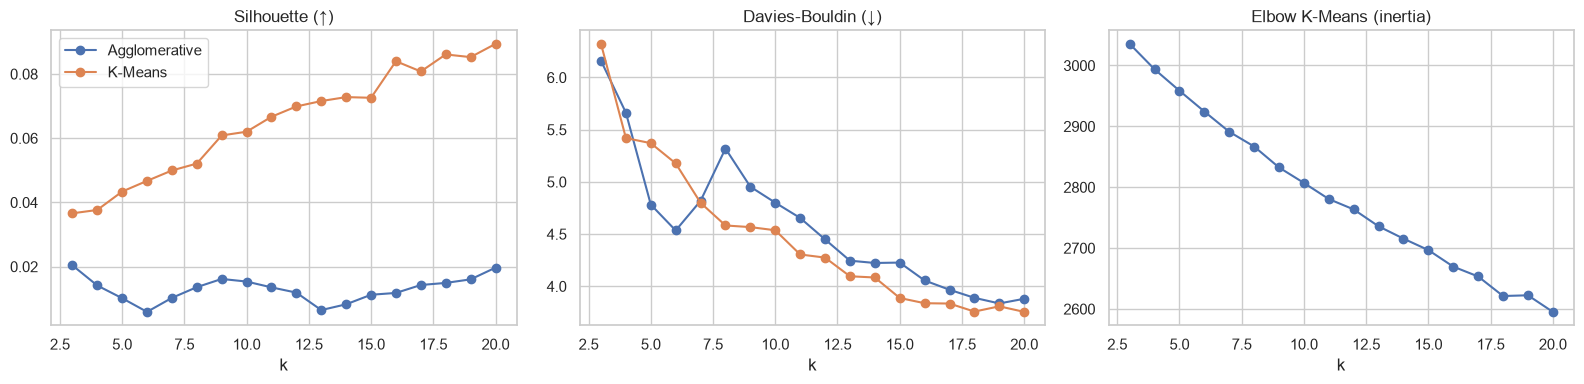

algoritma,Agglomerative,K-Means
k,,
3,0.0204,0.0366
4,0.0141,0.0376
5,0.0102,0.0434
6,0.0059,0.0467
7,0.0103,0.0499
8,0.0136,0.0521
9,0.0162,0.0609
10,0.0153,0.0620
11,0.0135,0.0667


In [6]:
hasil_k = []
for k in range(3, 21):
    for nama, model in [("K-Means", KMeans(n_clusters=k, n_init=10, random_state=SEED)),
                        ("Agglomerative", AgglomerativeClustering(n_clusters=k, linkage="ward"))]:
        lab = model.fit_predict(X)
        hasil_k.append(dict(algoritma=nama, k=k, silhouette=silhouette_score(X, lab, metric="cosine", random_state=SEED),
                            davies_bouldin=davies_bouldin_score(X, lab), calinski_harabasz=calinski_harabasz_score(X, lab),
                            inertia=getattr(model, "inertia_", np.nan)))
hasil_k = pd.DataFrame(hasil_k)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for nama, g in hasil_k.groupby("algoritma"):
    ax[0].plot(g.k, g.silhouette, marker="o", label=nama)
    ax[1].plot(g.k, g.davies_bouldin, marker="o", label=nama)
km = hasil_k[hasil_k.algoritma == "K-Means"]
ax[2].plot(km.k, km.inertia, marker="o", color="C0")
ax[0].set_title("Silhouette (↑)"); ax[1].set_title("Davies-Bouldin (↓)"); ax[2].set_title("Elbow K-Means (inertia)")
for a in ax: a.set_xlabel("k")
ax[0].legend(); plt.tight_layout(); plt.savefig(FIG / "04_pemilihan_k.png", dpi=150); plt.show()

pivot = hasil_k.pivot(index="k", columns="algoritma", values="silhouette")
pivot.round(4)

**Memilih algoritma dan *k*:**
- **Algoritma**: dibandingkan pada *k* yang sama, algoritma dengan silhouette lebih tinggi di sebagian besar *k* dipilih.
- ***k***: silhouette pada teks pendek cenderung **terus naik seiring bertambahnya k** (setiap klaster makin kecil dan spesifik),
  sehingga "silhouette tertinggi" selalu menunjuk batas atas rentang dan tidak bisa dipakai memilih *k*. Karena itu *k* dipilih dengan
  **metode elbow** (algoritma *kneedle*): titik pada kurva inertia yang jaraknya paling jauh dari garis lurus antara ujung-ujung kurva,
  yaitu titik di mana menambah klaster tidak lagi menurunkan inertia secara berarti.
- Nilai silhouette yang kecil (< 0,1) menunjukkan **batas antar topik tweet tidak tegas**. Ini wajar untuk tweet yang pendek dan
  bertopik campur, dan dibahas sebagai keterbatasan.

K-Means unggul silhouette pada 100% nilai k → algoritma dipilih: K-Means
k terpilih (elbow/kneedle) = 11


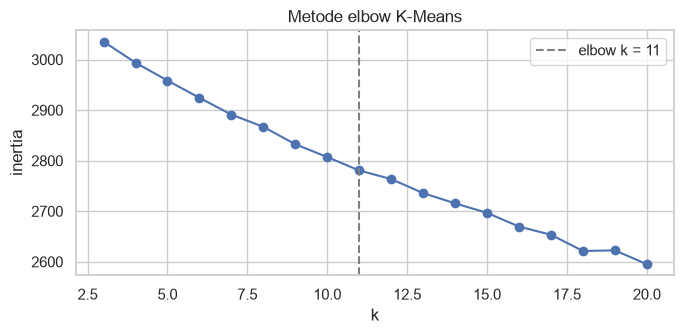

,k,silhouette,davies_bouldin,calinski_harabasz,inertia
algoritma,,,,,
K-Means,11,0.0667,4.3049,45.439,2780.5907
Agglomerative,11,0.0135,4.6546,30.233,NaN


In [7]:
menang = (pivot["K-Means"] > pivot["Agglomerative"]).mean()
ALGO = "K-Means" if menang >= 0.5 else "Agglomerative"
print(f"K-Means unggul silhouette pada {menang:.0%} nilai k → algoritma dipilih: {ALGO}")

def kneedle(x, y):
    """Titik siku kurva menurun: jarak terbesar antara kurva ternormalisasi dan garis lurus dari ujung ke ujung."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    xn, yn = (x - x[0]) / (x[-1] - x[0]), (y - y.min()) / (y.max() - y.min())
    garis = yn[0] + (yn[-1] - yn[0]) * xn
    return int(x[np.argmax(garis - yn)])

km = hasil_k[hasil_k.algoritma == "K-Means"].sort_values("k")
K = kneedle(km.k, km.inertia)
assert kneedle([1, 2, 3, 4, 5], [100, 40, 20, 15, 12]) == 2
print(f"k terpilih (elbow/kneedle) = {K}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(km.k, km.inertia, marker="o"); ax.axvline(K, ls="--", color="gray", label=f"elbow k = {K}")
ax.set_xlabel("k"); ax.set_ylabel("inertia"); ax.set_title("Metode elbow K-Means"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "04_elbow.png", dpi=150); plt.show()
hasil_k[(hasil_k.k == K)].set_index("algoritma").round(4)

In [8]:
model = KMeans(n_clusters=K, n_init=10, random_state=SEED) if ALGO == "K-Means" else AgglomerativeClustering(n_clusters=K, linkage="ward")
df["klaster"] = model.fit_predict(X)

**Pemeriksaan reprodusibilitas.** Label klaster tiap tweet dibandingkan dengan label acuan dari laptop memakai
*Adjusted Rand Index* (ARI; 1 = pembagian identik, tidak terpengaruh penomoran klaster). Sidik (hash) korpus dan fitur X
menunjukkan di tahap mana perbedaan muncul: korpus beda → preprocessing; X beda → komputasi numerik (CPU/BLAS).

In [9]:
import hashlib
from sklearn.metrics import adjusted_rand_score
jejak = dict(korpus=hashlib.md5("\n".join(df.text_clean).encode()).hexdigest()[:10],
             X=hashlib.md5(np.round(X, 5).tobytes()).hexdigest()[:10])
f_label = REF / "label_klaster_acuan.json"
if f_label.exists():
    acuan = json.loads(f_label.read_text(encoding="utf8"))
    print(f"Sidik korpus : {jejak['korpus']} (acuan {acuan['korpus']})")
    print(f"Sidik fitur X: {jejak['X']} (acuan {acuan['X']})")
    if len(acuan["label"]) == len(df):
        print(f"Kesepakatan label dengan acuan laptop (ARI): {adjusted_rand_score(acuan['label'], df.klaster):.4f}")
    else:
        print(f"Jumlah tweet berbeda: {len(df)} vs acuan {len(acuan['label'])}")
else:  # pertama kali di lingkungan acuan: simpan label sebagai acuan
    f_label.write_text(json.dumps(dict(jejak, label=df.klaster.tolist())), encoding="utf8")
    print("Label acuan disimpan:", f_label, jejak)

Label acuan disimpan: data\reference\label_klaster_acuan.json {'korpus': 'c55f88876c', 'X': 'b7752e76ce'}


## 5. Profil klaster
Kata kunci tiap klaster = kata dengan rata-rata bobot TF-IDF tertinggi di klaster tersebut.
Kolom `%laporan` = proporsi tweet yang diprediksi Naive Bayes sebagai laporan kejadian.

In [10]:
kosakata = np.array(tfidf.get_feature_names_out())
profil = []
for c in range(K):
    m = (df.klaster == c).values
    rata = np.asarray(X_tfidf[m].mean(axis=0)).ravel()
    profil.append(dict(klaster=c, jumlah=int(m.sum()), pct_laporan=round(100 * df.laporan[m].mean(), 1),
                       kata_kunci=", ".join(kosakata[rata.argsort()[::-1][:8]])))
profil = pd.DataFrame(profil).sort_values("pct_laporan", ascending=False)
profil

,klaster,jumlah,pct_laporan,kata_kunci
9,9,141,76.6,"tangerang, angka, kota, kabupaten, rumah, malam, hujan, deras"
5,5,165,37.0,"bekas, angka, rumah, kota, hujan, warga, bantu, kab"
6,6,510,32.7,"angka, jalan, rt, rumah, tahun, banjirjakarta, hujan, hari"
10,10,155,16.8,"bogor, kirim, longsor, bandang, angka, bantu, bencana, hujan"
8,8,228,12.7,"air, angka, mata, tanah, laut, masuk, genang, tidak"
4,4,950,11.3,"warga, sudah, hujan, buat, bukan, pak, jalan, apa"
2,2,196,11.2,"ciliwung, sungai, kali, angka, normalisasi, sodet, kurang, luap"
3,3,366,4.1,"tidak, angka, hujan, sudah, warga, kerja, macet, sama"
1,1,191,1.0,"gubernur, tidak, angka, hari, soal, malah, bukan, sudah"
0,0,315,0.6,"anies, baswedan, angka, kerja, pak, tidak, salah, tangan"


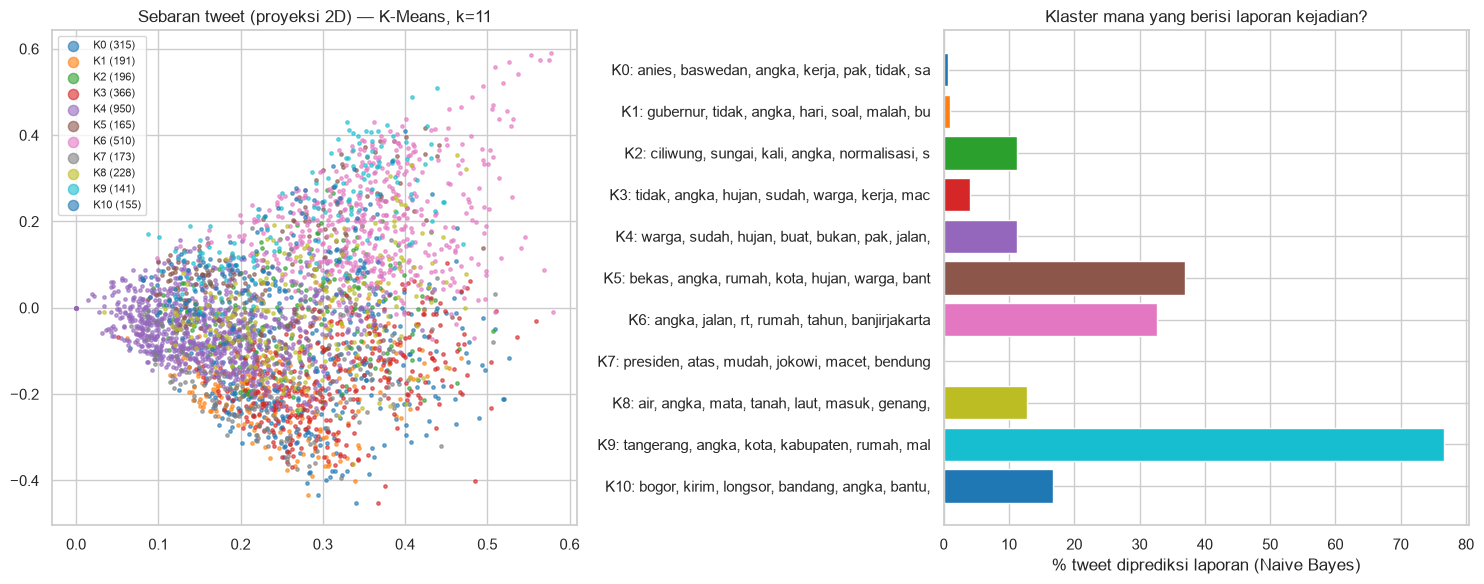

In [11]:
xy = TruncatedSVD(n_components=2, random_state=SEED).fit_transform(X)
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pal = sns.color_palette("tab10", K)
for c in range(K):
    m = df.klaster == c
    ax[0].scatter(xy[m, 0], xy[m, 1], s=6, color=pal[c], alpha=0.6, label=f"K{c} ({m.sum()})")
ax[0].set_title(f"Sebaran tweet (proyeksi 2D) — {ALGO}, k={K}"); ax[0].legend(markerscale=3, fontsize=8)
p = profil.sort_values("klaster")
ax[1].barh([f"K{c}: {kk[:45]}" for c, kk in zip(p.klaster, p.kata_kunci)], p.pct_laporan, color=[pal[c] for c in p.klaster])
ax[1].set_xlabel("% tweet diprediksi laporan (Naive Bayes)"); ax[1].invert_yaxis(); ax[1].set_title("Klaster mana yang berisi laporan kejadian?")
plt.tight_layout(); plt.savefig(FIG / "04_klaster.png", dpi=150); plt.show()

## 6. Mesin peringkasan: Hybrid TF-IDF
Hybrid TF-IDF (Sharifi, Hutton & Kalita, 2010) dirancang untuk teks pendek seperti tweet:
- **TF** dihitung atas **seluruh kumpulan tweet** sebagai satu dokumen: $TF(w) = \frac{\text{frekuensi } w \text{ di semua tweet}}{\text{total kata di semua tweet}}$
- **IDF** dihitung dengan **setiap tweet sebagai satu dokumen**: $IDF(w) = \log_2 \frac{N_\text{tweet}}{\text{jumlah tweet yang memuat } w}$
- **Skor tweet**: $S(t) = \dfrac{\sum_{w \in t} TF(w)\cdot IDF(w)}{\max(\text{ambang}, |t|)}$. Faktor normalisasi mencegah tweet panjang selalu menang.
- **Seleksi**: ambil tweet berskor tertinggi satu per satu, lewati tweet yang terlalu mirip (cosine > 0,77) dengan tweet yang
  sudah terpilih, agar ringkasan tidak berulang (Inouye & Kalita, 2011).

In [12]:
import inspect
from ringkas import hybrid_tfidf  # notebooks/ringkas.py: satu sumber kode untuk notebook dan acuan web
print(inspect.getsource(hybrid_tfidf))

def tfidf_standar(kalimat_bersih, n=3):
    """Baseline: jumlah bobot TF-IDF biasa per tweet tanpa normalisasi panjang dan tanpa cek redundansi."""
    v = TfidfVectorizer().fit_transform(kalimat_bersih)
    return [int(i) for i in np.asarray(v.sum(axis=1)).ravel().argsort()[::-1][:n]]

def acak(kalimat_bersih, n=3, seed=0):
    return random.Random(seed).sample(range(len(kalimat_bersih)), min(n, len(kalimat_bersih)))

# Uji kecil: tweet duplikat tidak boleh terpilih dua kali, tweet sangat pendek tidak boleh menang hanya karena pendek
uji = ["air setinggi angka sentimeter rendam jalan ciledug indah", "air setinggi angka sentimeter rendam jalan ciledug indah",
       "banjir", "warga evakuasi posko kantor camat ciledug", "lalu lintas macet total genang jalan raden saleh"]
p_uji, _ = hybrid_tfidf(uji, n=3)
assert not {0, 1} <= set(p_uji) and 2 not in p_uji, p_uji
print("✓ Uji redundansi dan normalisasi panjang lolos:", p_uji)

def tanpa_url(t):
    return re.sub(r"\s+", " ", re.sub(r"https?://\S+", "", t)).strip()

def hybrid_tfidf(kalimat_bersih, n=3, ambang=11, batas_mirip=0.77):
    """Kembalikan (indeks n tweet terpilih, skor semua tweet). `kalimat_bersih`: list teks hasil preprocess.

    TF dihitung atas seluruh kumpulan sebagai satu dokumen, IDF dengan tiap tweet sebagai dokumen,
    skor dinormalisasi panjang max(ambang, |tweet|). Tweet dengan cosine > batas_mirip terhadap yang
    sudah terpilih dilewati.
    """
    tok = [s.split() for s in kalimat_bersih]
    semua = Counter(w for t in tok for w in t)
    total = sum(semua.values())
    df_w = Counter(w for t in tok for w in set(t))
    N = len(tok)
    bobot = {w: (semua[w] / total) * math.log2(N / df_w[w]) for w in semua}
    skor = np.array([sum(bobot[w] for w in t) / max(ambang, len(t)) for t in tok])
    vec = [Counter(t) for t in tok]
    pilih = []
    for i in np.argsort(-skor, kind="stable"):  # skor tertinggi dulu; seri → indeks terkecil (deterministik, sama dgn web)
        if all(cosine(vec[i], vec[j]) <= batas_mirip for j

### Ringkasan setiap klaster (laporan situasi agen)
Hybrid TF-IDF tidak membedakan laporan dari opini atau iklan. Karena itu agen hanya meringkas tweet yang diprediksi
**laporan** oleh Naive Bayes (alur agen: klasifikasi → klasterisasi → peringkasan), bila klaster punya ≥ 10 tweet laporan.
Klaster opini/politik yang laporannya sedikit diringkas dari semua tweet-nya. Evaluasi ROUGE di bagian 7 tetap memakai
Hybrid TF-IDF murni pada set yang sama untuk semua metode, agar perbandingannya adil.

In [13]:
MIN_LAPORAN = 10
ringkasan = {}
for c in profil.klaster:
    sub = df[df.klaster == c]
    sumber = "laporan" if sub.laporan.sum() >= MIN_LAPORAN else "semua"
    sub = (sub[sub.laporan] if sumber == "laporan" else sub).reset_index(drop=True)
    pilih, skor = hybrid_tfidf(sub.text_clean.tolist(), n=3)
    ringkasan[int(c)] = [dict(text=sub.text_raw[i], waktu=str(sub.waktu[i].date()), skor=round(float(skor[i]), 6),
                              p_laporan=round(float(sub.p_laporan[i]), 3), sumber=sumber) for i in pilih]
    pr = profil.set_index("klaster").loc[c]
    print(f"\n■ Klaster {c} — {pr.jumlah} tweet, {pr.pct_laporan}% laporan | {pr.kata_kunci} | diringkas dari: {sumber} ({len(sub)})")
    for r in ringkasan[int(c)]:
        print(f"   • [{r['waktu']}] {tanpa_url(r['text'])[:170]}")


■ Klaster 9 — 141 tweet, 76.6% laporan | tangerang, angka, kota, kabupaten, rumah, malam, hujan, deras | diringkas dari: laporan (108)
   • [2022-12-30] Kondisi banjir genangi kawasan industri Olex Balaraja Kabupaten Tangerang Jumat (30/12/2022) sekitar pukul 17.00 WIB.
   • [2022-09-26] Banjir melanda beberapa wilayah Tangerang akibat hujan deras Senin (26/9/2022) malam.
   • [2019-05-15] Pasca banjir muncul ular sepanjang 4 5 meter di Perumahan Binong Permai Blok B Curug Kabupaten Tangerang Kamis (16/5/2019) pukul 01:00 WIB.

■ Klaster 5 — 165 tweet, 37.0% laporan | bekas, angka, rumah, kota, hujan, warga, bantu, kab | diringkas dari: laporan (61)
   • [2020-05-18] Banjir di wilayah Kelurahan Wanajaya Kecamatan Cibitung RW 07 Bekasi pada sore hari ini Senin 18/5/20.
   • [2023-02-25] BPBD Kabupaten Bekasi pada Sabtu (25/2) pukul 15.35 merilis data sebaran dampak banjir di Kabupaten Bekasi. Sebanyak 9 Kecamatan 20 Desa/Kelurahan di 43 titik di Kabupate
   • [2020-01-01] @RadioElshint

## 7. Evaluasi ringkasan dengan ROUGE
ROUGE mengukur tumpang-tindih kata antara ringkasan sistem dan **ringkasan acuan buatan manusia**:
- **ROUGE-1 / ROUGE-2**: tumpang-tindih unigram / bigram.
- **ROUGE-L**: *longest common subsequence*, memperhitungkan urutan kata.

**Set evaluasi**: dari setiap klaster diambil sampel 25 tweet (cukup kecil untuk dibaca manusia). Dua anggota kelompok
**menulis ringkasan acuan masing-masing secara terpisah tanpa bantuan AI**. Sistem dan baseline meringkas set yang sama.

In [14]:
N_SET, UKURAN_SET = 10, 25
SET_FILE = REF / "set_evaluasi.json"
posisi = {t: i for i, t in enumerate(df.text_raw)}
if SET_FILE.exists():
    # Set dikunci sejak pertama dibuat: lembar acuan yang sudah diisi tetap cocok walau klasterisasi diubah
    set_eval = [dict(s, idx=[posisi[t] for t in s["tweets"]]) for s in json.loads(SET_FILE.read_text(encoding="utf8"))]
else:
    rng = np.random.default_rng(SEED)
    urut = profil.sort_values("jumlah", ascending=False).klaster.tolist()
    alokasi = Counter(urut[i % len(urut)] for i in range(N_SET))  # klaster besar bisa dapat 2 set
    set_eval = []
    for c, n in sorted(alokasi.items()):
        idx = df.index[df.klaster == c].to_numpy()
        for j in range(n):
            ambil = rng.choice(idx, size=min(UKURAN_SET, len(idx)), replace=False)
            set_eval.append(dict(set_id=f"S{len(set_eval) + 1:02d}", klaster=int(c), idx=[int(i) for i in ambil]))
    SET_FILE.write_text(json.dumps([dict(set_id=s["set_id"], klaster_asal=s["klaster"], tweets=[df.text_raw[i] for i in s["idx"]])
                                    for s in set_eval], ensure_ascii=False, indent=1), encoding="utf8")
print(f"{len(set_eval)} set evaluasi:", [s["set_id"] for s in set_eval])

def tulis_lembar(path, penulis):
    baris = [f"# Lembar Ringkasan Acuan — {penulis}", "",
             "**Instruksi** (baca dulu):",
             "1. Kerjakan **sendiri**, jangan melihat lembar anggota lain, dan **jangan memakai AI** (ChatGPT, Gemini, dsb.).",
             "2. Untuk setiap set, baca ke-25 tweet, lalu tulis ringkasan **2–3 kalimat (±40–60 kata)** dengan kata-katamu sendiri:",
             "   apa yang terjadi, di mana, dan dampak/hal penting yang paling sering disebut.",
             "3. Tulis ringkasan **di antara baris `RINGKASAN:` dan `---`**. Jangan mengubah baris lain.",
             "4. Kalau tweet dalam satu set campur aduk, ringkas tema yang paling dominan.", ""]
    for s in set_eval:
        baris += [f"## {s['set_id']}", ""]
        baris += [f"{i}. {tanpa_url(df.text_raw[j])}" for i, j in enumerate(s["idx"], 1)]
        baris += ["", "RINGKASAN:", "", "---", ""]
    path.write_text("\n".join(baris), encoding="utf8")

for nama in ["izvio", "fatah"]:
    f = REF / f"lembar_acuan_{nama}.md"
    if not f.exists():  # jangan menimpa lembar yang sudah diisi
        tulis_lembar(f, nama.capitalize())
        print("Dibuat:", f)

def baca_lembar(path):
    isi = path.read_text(encoding="utf8")
    acuan = {}
    for m in re.finditer(r"## (S\d+)\s.*?RINGKASAN:\s*(.*?)\s*---", isi, flags=re.S):
        if m.group(2).strip():
            acuan[m.group(1)] = m.group(2).strip()
    return acuan

acuan = {n: baca_lembar(REF / f"lembar_acuan_{n}.md") for n in ["izvio", "fatah"]}
print({n: f"{len(a)}/{len(set_eval)} terisi" for n, a in acuan.items()})

10 set evaluasi: ['S01', 'S02', 'S03', 'S04', 'S05', 'S06', 'S07', 'S08', 'S09', 'S10']
{'izvio': '10/10 terisi', 'fatah': '10/10 terisi'}


In [15]:
def ngram(tok, n):
    return Counter(tuple(tok[i:i + n]) for i in range(len(tok) - n + 1))

def rouge_n(sis, ref, n):
    a, b = ngram(sis, n), ngram(ref, n)
    cocok = sum((a & b).values())
    p, r = cocok / max(sum(a.values()), 1), cocok / max(sum(b.values()), 1)
    return 2 * p * r / (p + r) if p + r else 0.0

def rouge_l(sis, ref):
    dp = [[0] * (len(ref) + 1) for _ in range(len(sis) + 1)]
    for i, x in enumerate(sis):
        for j, y in enumerate(ref):
            dp[i + 1][j + 1] = dp[i][j] + 1 if x == y else max(dp[i][j + 1], dp[i + 1][j])
    l = dp[-1][-1]
    p, r = l / max(len(sis), 1), l / max(len(ref), 1)
    return 2 * p * r / (p + r) if p + r else 0.0

def skor_rouge(teks_sistem, teks_acuan):
    s, r = teks.preprocess(teks_sistem).split(), teks.preprocess(teks_acuan).split()
    return dict(R1=rouge_n(s, r, 1), R2=rouge_n(s, r, 2), RL=rouge_l(s, r))

assert skor_rouge("air rendam jalan", "air rendam jalan")["R1"] == 1.0
assert skor_rouge("air rendam jalan", "macet total")["R1"] == 0.0

,R1,R2,RL
metode,,,
Hybrid TF-IDF,0.1760,0.0290,0.1177
Acak (rata-rata 20×),0.1744,0.0284,0.1190
TF-IDF standar,0.1492,0.0289,0.0979


Kesepakatan antar-anotator (ROUGE acuan Izvio vs Fatah): {'R1': 0.2978, 'R2': 0.0565, 'RL': 0.1639}


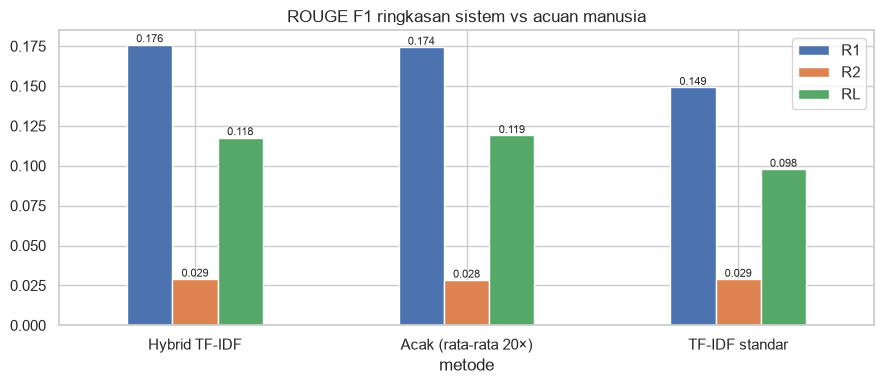

In [16]:
def ringkas_set(s, metode, seed=0):
    teks_set = [df.text_clean[i] for i in s["idx"]]
    if metode == "Hybrid TF-IDF":
        pilih = hybrid_tfidf(teks_set)[0]
    elif metode == "TF-IDF standar":
        pilih = tfidf_standar(teks_set)
    else:
        pilih = acak(teks_set, seed=seed)
    return " ".join(df.text_raw[s["idx"][i]] for i in pilih)

lengkap = all(len(a) == len(set_eval) for a in acuan.values())
if not any(acuan.values()):
    print("Belum ada ringkasan acuan. Isi data/reference/lembar_acuan_izvio.md dan lembar_acuan_fatah.md, lalu jalankan ulang bagian ini.")
else:
    if not lengkap:
        print("Peringatan: lembar acuan belum lengkap; evaluasi memakai set yang sudah terisi saja.")
    baris = []
    for s in set_eval:
        for penulis, a in acuan.items():
            if s["set_id"] not in a:
                continue
            for metode in ["Hybrid TF-IDF", "TF-IDF standar"]:
                baris.append(dict(set_id=s["set_id"], acuan=penulis, metode=metode, **skor_rouge(ringkas_set(s, metode), a[s["set_id"]])))
            acak_skor = pd.DataFrame([skor_rouge(ringkas_set(s, "Acak", seed), a[s["set_id"]]) for seed in range(20)]).mean()
            baris.append(dict(set_id=s["set_id"], acuan=penulis, metode="Acak (rata-rata 20×)", **acak_skor.to_dict()))
    evaluasi = pd.DataFrame(baris)
    tabel_rouge = evaluasi.groupby("metode")[["R1", "R2", "RL"]].mean().sort_values("R1", ascending=False).round(4)
    display(tabel_rouge)

    sepakat = [skor_rouge(acuan["izvio"][k], acuan["fatah"][k]) for k in acuan["izvio"] if k in acuan["fatah"]]
    if sepakat:
        print("Kesepakatan antar-anotator (ROUGE acuan Izvio vs Fatah):", pd.DataFrame(sepakat).mean().round(4).to_dict())

    ax = tabel_rouge.plot.bar(rot=0, figsize=(9, 4)); ax.set_title("ROUGE F1 ringkasan sistem vs acuan manusia")
    for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=8)
    plt.tight_layout(); plt.savefig(FIG / "04_rouge.png", dpi=150); plt.show()

### Apakah selisihnya bermakna? Uji berpasangan per set
Rata-rata ROUGE bisa berbeda karena kebetulan. Skor setiap set dirata-rata atas kedua acuan, lalu Hybrid TF-IDF dibandingkan
dengan tiap baseline **pada set yang sama** memakai uji **Wilcoxon signed-rank** (non-parametrik, cocok untuk 10 pasangan).
p < 0,05 berarti selisihnya kecil kemungkinannya terjadi karena kebetulan.

In [17]:
if any(acuan.values()):
    from scipy.stats import wilcoxon
    per_set = evaluasi.groupby(["set_id", "metode"])[["R1", "R2", "RL"]].mean().unstack("metode")
    uji = []
    for pembanding in ["Acak (rata-rata 20×)", "TF-IDF standar"]:
        for m in ["R1", "R2", "RL"]:
            h, b = per_set[(m, "Hybrid TF-IDF")], per_set[(m, pembanding)]
            uji.append(dict(pembanding=pembanding, metrik=m, unggul=f"{(h > b).sum()}/{len(h)} set",
                            selisih_rata2=round(float((h - b).mean()), 4), p_wilcoxon=round(float(wilcoxon(h, b).pvalue), 3)))
    uji = pd.DataFrame(uji)
    display(per_set.xs("R1", axis=1, level=0).round(3))
    display(uji)
    print("Signifikan (p < 0,05):", uji[uji.p_wilcoxon < 0.05][["pembanding", "metrik"]].values.tolist() or "tidak ada")

metode,Acak (rata-rata 20×),Hybrid TF-IDF,TF-IDF standar
set_id,,,
S01,0.163,0.199,0.110
S02,0.172,0.158,0.117
S03,0.203,0.222,0.235
S04,0.149,0.158,0.197
S05,0.200,0.181,0.182
S06,0.158,0.192,0.102
S07,0.160,0.131,0.152
S08,0.181,0.158,0.097
S09,0.162,0.188,0.135


,pembanding,metrik,unggul,selisih_rata2,p_wilcoxon
0,Acak (rata-rata 20×),R1,5/10 set,0.0016,0.770
1,Acak (rata-rata 20×),R2,3/10 set,0.0005,0.492
2,Acak (rata-rata 20×),RL,6/10 set,-0.0013,1.000
3,TF-IDF standar,R1,6/10 set,0.0268,0.160
4,TF-IDF standar,R2,6/10 set,0.0001,0.770
5,TF-IDF standar,RL,6/10 set,0.0198,0.160


Signifikan (p < 0,05): tidak ada


**Interpretasi** (dibahas di laporan BAB IV):
- Dua manusia pun hanya sebagian sepakat (lihat kesepakatan antar-anotator), sehingga skor ROUGE sistem perlu dibandingkan
  dengan angka itu, bukan dengan 1,0.
- Set evaluasi diambil dari satu klaster yang topiknya seragam, sehingga tweet acak pun sudah cukup mewakili topik. Ringkasan
  acuan ditulis dengan kata sendiri (abstraktif), sedangkan sistem memilih tweet utuh (ekstraktif).
- Dengan hanya 10 set, daya uji statistik kecil; selisih kecil tidak akan terdeteksi signifikan.

## 8. Ekspor untuk web dan simpan ke Supabase

In [18]:
teks.ekspor_json(EXPORT / "preprocessing.json")
sampel = df.sample(min(1500, len(df)), random_state=SEED).index
klaster_json = {
    "algoritma": ALGO, "k": K,
    "klaster": [dict(id=int(r.klaster), jumlah=int(r.jumlah), pct_laporan=float(r.pct_laporan), kata_kunci=r.kata_kunci,
                     ringkasan=ringkasan[int(r.klaster)]) for r in profil.itertuples()],
    "titik": [[round(float(xy[i, 0]), 4), round(float(xy[i, 1]), 4), int(df.klaster[i])] for i in sampel],
    "hybrid_tfidf": {"ambang": 11, "batas_mirip": 0.77, "n": 3},
}
(EXPORT / "klaster_ringkasan.json").write_text(json.dumps(klaster_json, ensure_ascii=False, separators=(",", ":")), encoding="utf8")
print("klaster_ringkasan.json:", round((EXPORT / "klaster_ringkasan.json").stat().st_size / 1024), "KB")

klaster_ringkasan.json: 37 KB


In [19]:
db_url = os.environ.get("SUPABASE_DB_URL")
if "google.colab" in sys.modules and not db_url:
    try:
        from google.colab import userdata
        db_url = userdata.get("SUPABASE_DB_URL")
    except Exception as e:  # tampilkan alasan (mis. Notebook access belum diizinkan)
        print(f"Gagal membaca secret: {type(e).__name__}: {e}")
        db_url = None

ukuran = lambda d: sorted(c["jumlah"] for c in d["klaster"])
sama_acuan = klaster_acuan is None or ukuran(klaster_acuan) == ukuran(klaster_json)
if klaster_acuan is not None and sama_acuan:
    print("✓ Hasil klaster identik dengan acuan di repo:", ukuran(klaster_json))
if not sama_acuan:
    print("⚠ Hasil klaster berbeda dengan versi acuan di repo (kemungkinan versi library berbeda).\n"
          "  Supabase TIDAK ditimpa agar tetap konsisten dengan laporan dan web.")
elif not db_url:
    print("SUPABASE_DB_URL tidak ditemukan — penyimpanan ke Supabase dilewati.")
else:
    import psycopg2
    from psycopg2.extras import execute_values, Json
    with psycopg2.connect(db_url) as conn, conn.cursor() as cur:
        cur.execute("truncate uts_ai_bencana.summaries restart identity")
        execute_values(cur, "insert into uts_ai_bencana.summaries (period, n_tweets, summary) values %s",
                       [(f"klaster-{int(r.klaster)}", int(r.jumlah),
                         Json(dict(kata_kunci=r.kata_kunci, pct_laporan=float(r.pct_laporan), algoritma=ALGO,
                                   tweets=ringkasan[int(r.klaster)]))) for r in profil.itertuples()])
    print(f"✓ Tersimpan: {len(profil)} ringkasan klaster")

✓ Hasil klaster identik dengan acuan di repo: [141, 155, 165, 173, 191, 196, 228, 315, 366, 510, 950]
SUPABASE_DB_URL tidak ditemukan — penyimpanan ke Supabase dilewati.
